# Project 09 · A/B Experiment: Checkout Conversion from Scratch

**Track:** Experimentation  
**Research / product question:** Does a simplified e-commerce checkout improve conversion while protecting revenue and latency?

**Learning outcome:** Random assignment, SRM checks, difference in proportions, power, CUPED, confidence intervals and ship decision.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

Analyze a user-randomized treatment with a conversion-rate estimand, SRM check, sampling uncertainty, CUPED covariate adjustment and pre-declared latency guardrail.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Simulate a randomized online experiment

Users are independently randomized. Each has a pre-experiment activity measure related to conversion and a device segment. Treatment changes true conversion probability; these assumptions are built into the simulator.

           purchase  revenue  latency_ms
treatment                               
0             0.076    5.604     448.537
1             0.091    6.804     474.885


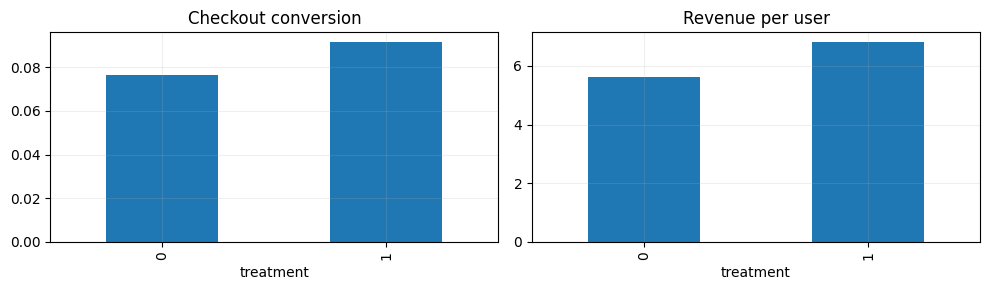

In [2]:
# User-randomized treatment, synthetic purchases and pre-treatment covariates.
from scipy.stats import norm,chisquare
n=24000
uid=np.arange(n);D=rng.binomial(1,.5,n);mobile=rng.binomial(1,.62,n)
pre_activity=rng.gamma(2.1,2.0,n)
base=-2.5+.18*(pre_activity-4)-.28*mobile
p0=1/(1+np.exp(-base));p1=1/(1+np.exp(-(base+.20)))
Y=rng.binomial(1,np.where(D==1,p1,p0))
revenue=Y*rng.lognormal(4.2,.45,n)
latency=rng.normal(430+26*D+30*mobile,80,n)
frame=pd.DataFrame({'user_id':uid,'treatment':D,'mobile':mobile,'pre_activity':pre_activity,'purchase':Y,'revenue':revenue,'latency_ms':latency})
print(frame.groupby('treatment')[['purchase','revenue','latency_ms']].mean().round(3).to_string())
fig,ax=plt.subplots(1,2,figsize=(10,3));frame.groupby('treatment').purchase.mean().plot.bar(ax=ax[0],title='Checkout conversion');frame.groupby('treatment').revenue.mean().plot.bar(ax=ax[1],title='Revenue per user');plt.tight_layout();plt.show()

## 2. Quality checks, SRM and effect estimate

A Sample Ratio Mismatch check compares treatment counts to the **planned** 50/50 allocation. Use the original assignment unit for all metric analyses.

In [3]:
# SRM, two-proportion effect and confidence interval.
counts=frame.treatment.value_counts().reindex([0,1]);srm_p=chisquare(counts, f_exp=[n/2,n/2]).pvalue
p_t=frame.loc[frame.treatment==1,'purchase'].mean();p_c=frame.loc[frame.treatment==0,'purchase'].mean()
n1=counts[1];n0=counts[0];se=np.sqrt(p_t*(1-p_t)/n1+p_c*(1-p_c)/n0)
effect=p_t-p_c;z=effect/se;pval=2*norm.sf(abs(z));ci=(effect-1.96*se,effect+1.96*se)
print('SRM p:',round(srm_p,4),'Control/Treatment sample sizes:',counts.to_dict())
print('Conversion effect:',round(effect,4),'95% CI:',tuple(round(x,4) for x in ci),'p:',round(pval,5))

SRM p: 0.38 Control/Treatment sample sizes: {0: 11932, 1: 12068}
Conversion effect: 0.015 95% CI: (np.float64(0.008), np.float64(0.0221)) p: 3e-05


## 3. Power analysis and CUPED variance reduction

CUPED subtracts a coefficient times the mean-centered pre-treatment covariate. Because the covariate precedes randomization, it cannot be affected by treatment. For clarity, estimate variance reduction and uncertainty at the user level.

In [4]:
# Estimate planning power and CUPED adjustment from pre-treatment activity.
from statsmodels.stats.power import NormalIndPower
# Normal approximation to proportions at baseline p0 and planning MDE.
planning_p=.09;mde=.012;sigma=np.sqrt(2*planning_p*(1-planning_p))
required=NormalIndPower().solve_power(effect_size=mde/sigma,alpha=.05,power=.8,ratio=1)
print('Approximate required users per arm for 1.2pp effect:',round(required))
Xpre=frame.pre_activity.to_numpy();centered=Xpre-Xpre.mean();theta=np.cov(Y,Xpre,ddof=1)[0,1]/np.var(Xpre,ddof=1)
adjusted=Y-theta*centered
frame['cuped_outcome']=adjusted
raw_var=Y.var(ddof=1);cuped_var=adjusted.var(ddof=1)
print('CUPED theta:',round(theta,4),'variance reduction:',round(1-cuped_var/raw_var,3))
def mean_effect_and_ci(values,d):
 a=values[d==1];b=values[d==0];effect=a.mean()-b.mean()
 s=np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
 return effect,(effect-1.96*s,effect+1.96*s)
raw=mean_effect_and_ci(Y,D);cuped=mean_effect_and_ci(adjusted,D)
print('Raw 95% CI',raw,'CUPED 95% CI',cuped)

Approximate required users per arm for 1.2pp effect: 17856
CUPED theta: 0.017 variance reduction: 0.032
Raw 95% CI (np.float64(0.015048483223516845), (np.float64(0.00803501920769542), np.float64(0.02206194723933827))) CUPED 95% CI (np.float64(0.01460774176992656), (np.float64(0.007706293839093209), np.float64(0.021509189700759913)))


## 4. Bootstrap and decision table

The treatment is randomized, so user-level bootstrap resamples are appropriate for independently assigned users. Guardrail latency worsens by design; whether the experiment ships depends on a **predeclared** threshold.

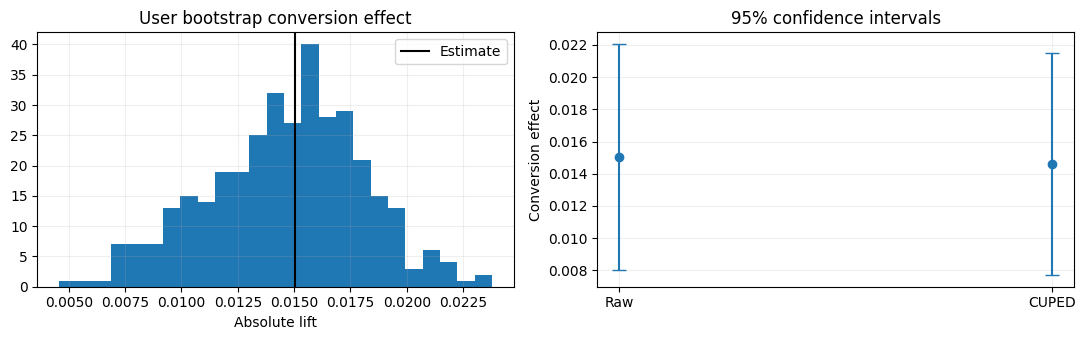

Bootstrap 95% CI: (np.float64(0.0076), np.float64(0.021)) Latency guardrail change (ms): 26.3
Decision example: Review guardrail before ship


In [5]:
# Cross-check uncertainty using user-level bootstrap.
r=np.random.default_rng(100);control=np.where(D==0)[0];treated=np.where(D==1)[0]
boot=[]
for _ in range(350):
    a=r.choice(treated,len(treated),replace=True);b=r.choice(control,len(control),replace=True)
    boot.append(Y[a].mean()-Y[b].mean())
boot_ci=np.quantile(boot,[.025,.975]);latency_effect=frame.loc[D==1,'latency_ms'].mean()-frame.loc[D==0,'latency_ms'].mean()
fig,ax=plt.subplots(1,2,figsize=(11,3.5));ax[0].hist(boot,bins=25);ax[0].axvline(effect,color='k',label='Estimate');ax[0].legend();ax[0].set(title='User bootstrap conversion effect',xlabel='Absolute lift');
ax[1].errorbar([0,1],[raw[0],cuped[0]],yerr=[[raw[0]-raw[1][0],cuped[0]-cuped[1][0]],[raw[1][1]-raw[0],cuped[1][1]-cuped[0]]],fmt='o',capsize=5)
ax[1].set(xticks=[0,1],xticklabels=['Raw','CUPED'],ylabel='Conversion effect',title='95% confidence intervals');plt.tight_layout();plt.show()
print('Bootstrap 95% CI:',tuple(np.round(boot_ci,4)),'Latency guardrail change (ms):',round(latency_effect,1))
print('Decision example:', 'Review guardrail before ship' if latency_effect>20 else 'Review conversion and cost for ship')

## What the results mean / interview discussion

A/B analysis requires trusted randomization, one primary decision metric and pre-specified guardrails. CUPED can increase precision without changing the randomized estimand. Do not overinterpret post-hoc segment scans or repeatedly peek at fixed-horizon p-values.

**Try explaining these without looking at the code:**

1. What does a p-value *not* tell you?
2. Why is pre-treatment CUPED valid but controlling for post-treatment page views dangerous?
3. How would you pre-specify practical significance and latency guardrails?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Decision principle:** statistical significance is not a launch decision. Calculate absolute lift, confidence interval, cost/latency impact and the cost of mistakes. CUPED covariates must be measured before treatment.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.